# Exploração e Visualização das Funções de Custo

Este notebook explora, visualiza e simula as **3 funções de custo fundamentais** implementadas em `mlp.custos`:
1. **MSE (Mean Squared Error)** — Erro Quadrático Médio para tarefas de **Regressão**.
2. **BCE (Binary Cross-Entropy)** — Entropia Cruzada Binária para **Classificação Binária** (combinada com Sigmoide).
3. **CCE (Categorical Cross-Entropy)** — Entropia Cruzada Categórica para **Classificação Multiclasse** (combinada com Softmax).


In [1]:
import sys
from pathlib import Path

# Garante que a raiz do projeto esteja no sys.path ao rodar da pasta parciais/
raiz_projeto = Path.cwd().parent if Path.cwd().name == "parciais" else Path.cwd()
if str(raiz_projeto) not in sys.path:
    sys.path.insert(0, str(raiz_projeto))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mlp.custos import BCE, CCE, MSE

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


## 1. MSE (Mean Squared Error) — Regressão

O Erro Quadrático Médio penaliza desvios entre a predição $\hat{y}$ e o alvo contínuo $y$ com crescimento quadrático:
$$L(y, \hat{y}) = \frac{1}{N} \sum_{i=1}^N \|y_i - \hat{y}_i\|^2$$

Sua derivada em relação à predição cresce linearmente com o erro:
$$\frac{\partial L}{\partial \hat{y}} = \frac{2}{N} (\hat{y} - y)$$

Abaixo visualizamos a parábola de custo e a reta de gradiente para um alvo fixo $y = 2{,}0$, além da superfície convexa 2D de parâmetros $(w, b)$ para um ajuste linear.


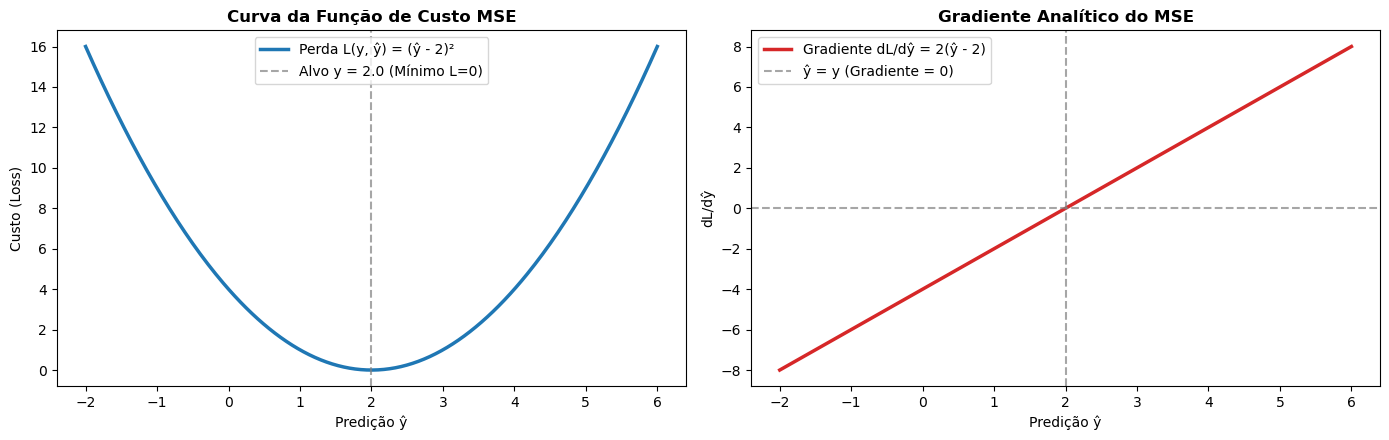

In [2]:
mse = MSE()
y_fixo = np.array([[2.0]])
y_preds = np.linspace(-2.0, 6.0, 300).reshape(-1, 1)

perdas_mse = [mse.calcular_custo(y_fixo, p.reshape(1, 1)) for p in y_preds]
gradientes_mse = [float(mse.gradiente(y_fixo, p.reshape(1, 1))[0, 0]) for p in y_preds]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ax1.plot(y_preds.ravel(), perdas_mse, color="#1f77b4", lw=2.5, label="Perda L(y, ŷ) = (ŷ - 2)²")
ax1.axvline(2.0, color="gray", linestyle="--", alpha=0.7, label="Alvo y = 2.0 (Mínimo L=0)")
ax1.set_title("Curva da Função de Custo MSE", fontsize=12, fontweight="bold")
ax1.set_xlabel("Predição ŷ")
ax1.set_ylabel("Custo (Loss)")
ax1.legend()

ax2.plot(y_preds.ravel(), gradientes_mse, color="#d62728", lw=2.5, label="Gradiente dL/dŷ = 2(ŷ - 2)")
ax2.axhline(0, color="gray", linestyle="--", alpha=0.7)
ax2.axvline(2.0, color="gray", linestyle="--", alpha=0.7, label="ŷ = y (Gradiente = 0)")
ax2.set_title("Gradiente Analítico do MSE", fontsize=12, fontweight="bold")
ax2.set_xlabel("Predição ŷ")
ax2.set_ylabel("dL/dŷ")
ax2.legend()

plt.tight_layout()
plt.show()


## 2. BCE (Binary Cross-Entropy) — Classificação Binária

A Entropia Cruzada Binária mede a divergência entre rótulos verdadeiros $y \in \{0, 1\}$ e probabilidades previstas $\hat{y} \in (0, 1)$:
$$L(y, \hat{y}) = -\frac{1}{N} \sum_{i=1}^N \left[ y_i \ln(\hat{y}_i) + (1 - y_i) \ln(1 - \hat{y}_i) \right]$$

### Por que usar BCE em vez de MSE na Classificação?
Quando combinada com a Sigmoide $\hat{y} = \sigma(z)$, a derivada da BCE cancela exatamente o termo $\hat{y}(1 - \hat{y})$ da Sigmoide:
$$\frac{\partial L}{\partial z} = \frac{\partial L}{\partial \hat{y}} \cdot \sigma'(z) = \frac{\hat{y} - y}{\hat{y}(1 - \hat{y})} \cdot \hat{y}(1 - \hat{y}) = \mathbf{\hat{y} - y}$$
Isso impede o desvanecimento do gradiente quando a rede erra grosseiramente, enquanto o MSE causa um platô horizontal onde o gradiente quase zera!


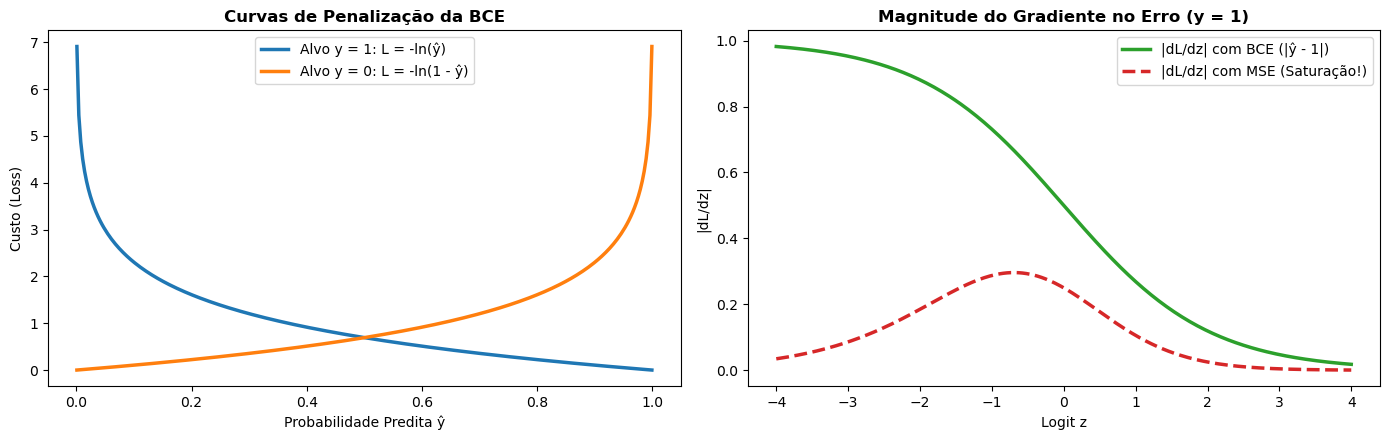

In [3]:
bce = BCE()
y_prob = np.linspace(0.001, 0.999, 300).reshape(-1, 1)

perda_bce_y1 = [bce.calcular_custo(np.array([[1.0]]), p.reshape(1, 1)) for p in y_prob]
perda_bce_y0 = [bce.calcular_custo(np.array([[0.0]]), p.reshape(1, 1)) for p in y_prob]

# Comparação do Gradiente em relação a z (pré-ativação) para y=1
z_vals = np.linspace(-4, 4, 300)
sig_vals = 1.0 / (1.0 + np.exp(-z_vals))
grad_bce_z = sig_vals - 1.0  # (ŷ - y) = σ(z) - 1
grad_mse_z = 2.0 * (sig_vals - 1.0) * (sig_vals * (1.0 - sig_vals))  # 2(ŷ - y) * σ'(z)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ax1.plot(y_prob.ravel(), perda_bce_y1, color="#1f77b4", lw=2.5, label="Alvo y = 1: L = -ln(ŷ)")
ax1.plot(y_prob.ravel(), perda_bce_y0, color="#ff7f0e", lw=2.5, label="Alvo y = 0: L = -ln(1 - ŷ)")
ax1.set_title("Curvas de Penalização da BCE", fontsize=12, fontweight="bold")
ax1.set_xlabel("Probabilidade Predita ŷ")
ax1.set_ylabel("Custo (Loss)")
ax1.legend()

ax2.plot(z_vals, np.abs(grad_bce_z), color="#2ca02c", lw=2.5, label="|dL/dz| com BCE (|ŷ - 1|)")
ax2.plot(z_vals, np.abs(grad_mse_z), color="#d62728", lw=2.5, linestyle="--", label="|dL/dz| com MSE (Saturação!)")
ax2.set_title("Magnitude do Gradiente no Erro (y = 1)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Logit z")
ax2.set_ylabel("|dL/dz|")
ax2.legend()

plt.tight_layout()
plt.show()


## 3. CCE (Categorical Cross-Entropy) — Classificação Multiclasse

A Entropia Cruzada Categórica quantifica a perda em classificações com $C \ge 3$ classes mutualmente exclusivas:
$$L(y, \hat{y}) = -\frac{1}{N} \sum_{i=1}^N \sum_{c=1}^C y_{ic} \ln(\hat{y}_{ic})$$

Abaixo simulamos três cenários de inferência para uma amostra cujo alvo real é a **Classe 0** ($y = [1, 0, 0]$):
1. **Predição Confiante e Correta:** $\hat{y} = [0{,}95, 0{,}03, 0{,}02] \implies L \approx 0{,}05$.
2. **Predição em Dúvida (Uniforme):** $\hat{y} = [0{,}33, 0{,}33, 0{,}33] \implies L = \ln(3) \approx 1{,}10$.
3. **Predição Confiante mas Errada:** $\hat{y} = [0{,}01, 0{,}98, 0{,}01] \implies L = -\ln(0{,}01) \approx 4{,}60$.


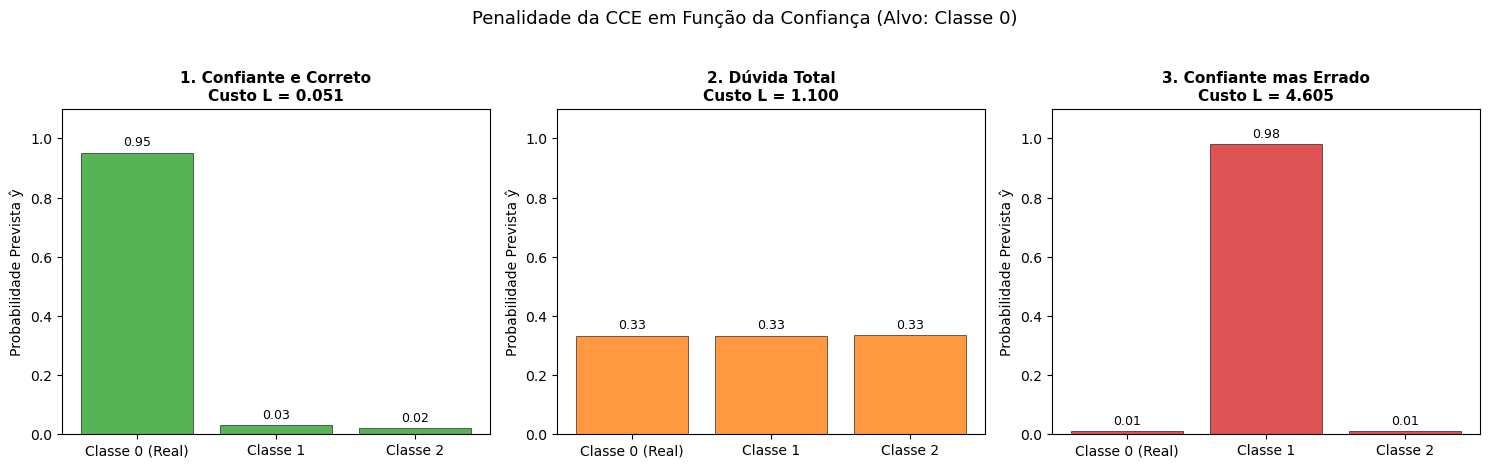

,Cenário,P(Classe 0 Correta),Perda CCE (Loss),dL / dP_0
0,1. Confiante e Correto,0.950,0.0513,-1.05
1,2. Dúvida Total,0.333,1.0996,-3.00
2,3. Confiante mas Errado,0.010,4.6052,-100.00


In [4]:
cce = CCE()
y_true_cce = np.array([[1.0, 0.0, 0.0]])

cenarios = {
    "1. Confiante e Correto": np.array([[0.95, 0.03, 0.02]]),
    "2. Dúvida Total": np.array([[0.333, 0.333, 0.334]]),
    "3. Confiante mas Errado": np.array([[0.01, 0.98, 0.01]]),
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
classes = ["Classe 0 (Real)", "Classe 1", "Classe 2"]
cores_cenarios = ["#2ca02c", "#ff7f0e", "#d62728"]
linhas_cce = []

for ax, (nome, pred), cor in zip(axes, cenarios.items(), cores_cenarios, strict=True):
    loss = cce.calcular_custo(y_true_cce, pred)
    grad = cce.gradiente(y_true_cce, pred)[0]

    linhas_cce.append(
        {
            "Cenário": nome,
            "P(Classe 0 Correta)": f"{pred[0, 0]:.3f}",
            "Perda CCE (Loss)": f"{loss:.4f}",
            "dL / dP_0": f"{grad[0]:.2f}",
        }
    )

    bars = ax.bar(classes, pred[0], color=cor, alpha=0.8, edgecolor="black", linewidth=0.5)
    ax.set_ylim(0, 1.1)
    ax.set_title(f"{nome}\nCusto L = {loss:.3f}", fontsize=11, fontweight="bold")
    ax.set_ylabel("Probabilidade Prevista ŷ")

    for bar in bars:
        h = bar.get_height()
        ax.annotate(
            f"{h:.2f}",
            xy=(bar.get_x() + bar.get_width() / 2, h),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
        )

plt.suptitle("Penalidade da CCE em Função da Confiança (Alvo: Classe 0)", fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

pd.DataFrame(linhas_cce)


## 4. Validação das Derivadas Analíticas (Gradiente vs. Diferenças Finitas)

Para comprovar a correção matemática exata do método `gradiente(y_true, y_pred)`, comparamos o gradiente analítico implementado com o gradiente numérico aproximado por diferenças finitas centrais:
$$\frac{\partial L_{\text{num}}}{\partial \hat{y}_{ij}} = \frac{L(\hat{y} + \epsilon e_{ij}) - L(\hat{y} - \epsilon e_{ij})}{2\epsilon}, \quad \text{com } \epsilon = 10^{-6}$$


In [5]:
resumo_gradientes = []
eps = 1e-6
rng = np.random.RandomState(42)

# 1. MSE
y_true_mse = rng.randn(4, 2)
y_pred_mse = rng.randn(4, 2)
grad_ana_mse = mse.gradiente(y_true_mse, y_pred_mse)
grad_num_mse = np.zeros_like(y_pred_mse)
for i in range(y_pred_mse.shape[0]):
    for j in range(y_pred_mse.shape[1]):
        yp_m = y_pred_mse.copy()
        yp_m[i, j] += eps
        yp_l = y_pred_mse.copy()
        yp_l[i, j] -= eps
        grad_num_mse[i, j] = (
            mse.calcular_custo(y_true_mse, yp_m) - mse.calcular_custo(y_true_mse, yp_l)
        ) / (2 * eps)
erro_mse = np.max(np.abs(grad_ana_mse - grad_num_mse))
resumo_gradientes.append(
    {
        "Função de Custo": "MSE",
        "Aplicação": "Regressão",
        "Max Erro Absoluto": f"{erro_mse:.2e}",
        "Concordância": "Excelente (< 1e-5)" if erro_mse < 1e-4 else "Atenção",
    }
)

# 2. BCE
y_true_bce = rng.randint(0, 2, size=(4, 1)).astype(np.float64)
y_pred_bce = rng.uniform(0.2, 0.8, size=(4, 1))
grad_ana_bce = bce.gradiente(y_true_bce, y_pred_bce)
grad_num_bce = np.zeros_like(y_pred_bce)
for i in range(y_pred_bce.shape[0]):
    yp_m = y_pred_bce.copy()
    yp_m[i, 0] += eps
    yp_l = y_pred_bce.copy()
    yp_l[i, 0] -= eps
    grad_num_bce[i, 0] = (
        bce.calcular_custo(y_true_bce, yp_m) - bce.calcular_custo(y_true_bce, yp_l)
    ) / (2 * eps)
erro_bce = np.max(np.abs(grad_ana_bce - grad_num_bce))
resumo_gradientes.append(
    {
        "Função de Custo": "BCE",
        "Aplicação": "Classificação Binária",
        "Max Erro Absoluto": f"{erro_bce:.2e}",
        "Concordância": "Excelente (< 1e-5)" if erro_bce < 1e-4 else "Atenção",
    }
)

# 3. CCE
y_true_cce_t = np.array([[1.0, 0.0, 0.0], [0.0, 1.0, 0.0]])
y_pred_cce_t = np.array([[0.6, 0.3, 0.1], [0.2, 0.5, 0.3]])
grad_ana_cce = cce.gradiente(y_true_cce_t, y_pred_cce_t)
grad_num_cce = np.zeros_like(y_pred_cce_t)
for i in range(y_pred_cce_t.shape[0]):
    for j in range(y_pred_cce_t.shape[1]):
        yp_m = y_pred_cce_t.copy()
        yp_m[i, j] += eps
        yp_l = y_pred_cce_t.copy()
        yp_l[i, j] -= eps
        grad_num_cce[i, j] = (
            cce.calcular_custo(y_true_cce_t, yp_m) - cce.calcular_custo(y_true_cce_t, yp_l)
        ) / (2 * eps)
erro_cce = np.max(np.abs(grad_ana_cce - grad_num_cce))
resumo_gradientes.append(
    {
        "Função de Custo": "CCE",
        "Aplicação": "Classificação Multiclasse",
        "Max Erro Absoluto": f"{erro_cce:.2e}",
        "Concordância": "Excelente (< 1e-5)" if erro_cce < 1e-4 else "Atenção",
    }
)

pd.DataFrame(resumo_gradientes)


,Função de Custo,Aplicação,Max Erro Absoluto,Concordância
0,MSE,Regressão,5.10e-10,Excelente (< 1e-5)
1,BCE,Classificação Binária,6.37e-11,Excelente (< 1e-5)
2,CCE,Classificação Multiclasse,2.88e-11,Excelente (< 1e-5)
